# 03 · Bobot Indeks Risiko: Manual atau dari Data?

**Pertanyaan:** bobot indeks risiko v1 (hujan 72 jam 30, prakiraan 25, debit 25, riwayat 20) ditetapkan manual di plan §6.3. Apakah bobot yang dipelajari dari data menghasilkan indeks yang lebih baik?

**Cara menjawab:**

1. Bangun data harian musim hujan Jakarta 2017/18–2024/25: skor tiap komponen pada pukul 00 WIB, plus jumlah laporan banjir Jabodetabek hari itu.
2. **Uji kepekaan:** nilai 231 kombinasi bobot. Apakah bobot manual jauh dari yang terbaik?
3. **Bobot dari data:** regresi logistik dengan koefisien ≥ 0, divalidasi *leave-one-season-out* (latih 7 musim, uji 1 musim, ulangi 8 kali).
4. **Bootstrap per musim:** apakah selisihnya lebih besar dari variasi kebetulan?

Semua run dicatat di MLflow (eksperimen `siaganusa-indeks-risiko`).

**Batasan yang perlu diingat sejak awal:**

- **Komponen prakiraan memakai hujan ERA5 hari itu** sebagai pengganti prakiraan, karena arsip prakiraan baru dikumpulkan sejak November 2026. Ini prakiraan sempurna, jadi bobot prakiraan cenderung terlalu tinggi.
- **Komponen riwayat banjir tidak diuji.** Untuk Jakarta nilainya konstan, jadi tidak mengubah urutan hari dan tidak memengaruhi AUC.
- **Label bergantung pada jumlah pengguna PetaBencana**, yang berubah dari tahun ke tahun.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd

from pipeline import backtest as bt
from pipeline.config import settings
from pipeline.db import engine
from pipeline.risk import WEIGHTS

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)

mlflow.set_tracking_uri(settings.mlflow_tracking_uri)
EXPERIMENT = "siaganusa-indeks-risiko"
mlflow.set_experiment(EXPERIMENT)  # dibuat otomatis kalau belum ada; artefak disimpan server

LABELS = (5, 20, 50)          # hari dengan ≥k laporan banjir di Jabodetabek
MAIN = 20                     # label utama
COMMON_TAGS = {"city": "jakarta", "seasons": "2017/18-2024/25", "forecast_proxy": "era5_same_day",
               "label": "laporan banjir Jabodetabek per hari WIB"}

2026/11/23 14:39:00 INFO mlflow.tracking.fluent: Experiment with name 'siaganusa-indeks-risiko' does not exist. Creating a new experiment.


## 1. Data

In [2]:
df = bt.build_dataset(engine, "jakarta")
Y = {k: (df["n_reports"] >= k).to_numpy() for k in LABELS}

events = pd.DataFrame({f"≥{k} laporan": pd.Series(Y[k]).groupby(df["season"].to_numpy()).sum() for k in LABELS})
events.index = [f"{s}/{str(s + 1)[2:]}" for s in events.index]
events.loc["total"] = events.sum()
print(f"{len(df)} hari musim hujan, {df['season'].nunique()} musim")
events

1450 hari musim hujan, 8 musim


,≥5 laporan,≥20 laporan,≥50 laporan
2017/18,55,12,1
2018/19,3,2,0
2019/20,42,11,8
2020/21,15,6,2
2021/22,6,1,0
2022/23,11,0,0
2023/24,44,4,0
2024/25,21,5,1
total,197,41,12


Kejadian banjir besar sangat sedikit, dan sebarannya tidak merata antarmusim. Musim 2022/23 tidak punya satu pun hari dengan ≥20 laporan. Ini alasan memakai validasi per musim: satu pembagian latih/uji saja akan sangat bergantung pada musim mana yang kebetulan masuk data uji.

In [3]:
df[list(bt.COMPONENTS)].describe().loc[["mean", "50%", "max"]].rename(index={"50%": "median"})

,rain_72h,forecast,river
mean,0.253,0.02,0.251
median,0.007,0.00,0.003
max,0.997,0.60,0.997


## 2. Bobot manual dan pembanding sederhana

Bobot tetap tidak perlu dilatih, jadi langsung dinilai di semua hari. Bobot manual dinormalkan untuk 3 komponen: 30/25/25 → 0,375/0,3125/0,3125.

In [4]:
total = sum(WEIGHTS[c] for c in bt.COMPONENTS)
SCHEMES = {
    "manual-v1": {c: WEIGHTS[c] / total for c in bt.COMPONENTS},
    "sama-rata": {c: 1 / 3 for c in bt.COMPONENTS},
    "hanya-hujan72": {"rain_72h": 1, "forecast": 0, "river": 0},
    "hanya-prakiraan": {"rain_72h": 0, "forecast": 1, "river": 0},
    "hanya-debit": {"rain_72h": 0, "forecast": 0, "river": 1},
}

rows, scores = [], {}
for name, w in SCHEMES.items():
    s = bt.weighted_score(df, w)
    scores[name] = s
    m = {f"{key}_ge{k}": v for k in LABELS for key, v in bt.metrics(Y[k], s).items()}
    rows.append({"skema": name, **{f"w_{c}": w[c] for c in bt.COMPONENTS}, **m})
    with mlflow.start_run(run_name=name):
        mlflow.set_tags({**COMMON_TAGS, "method": "bobot tetap", "validation": "semua hari (tanpa pelatihan)"})
        mlflow.log_params({f"w_{c}": round(w[c], 4) for c in bt.COMPONENTS})
        mlflow.log_metrics(m)
fixed = pd.DataFrame(rows).set_index("skema")
fixed[[f"auc_ge{k}" for k in LABELS] + [f"ap_ge{k}" for k in LABELS]]

🏃 View run manual-v1 at: http://127.0.0.1:5000/#/experiments/3/runs/edec21cccea441f0a55ce1b5c6d4bcd7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
🏃 View run sama-rata at: http://127.0.0.1:5000/#/experiments/3/runs/434481379ec64b51abba4af5de9aeede
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


🏃 View run hanya-hujan72 at: http://127.0.0.1:5000/#/experiments/3/runs/e64121de41844aebacacf56e9173730c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
🏃 View run hanya-prakiraan at: http://127.0.0.1:5000/#/experiments/3/runs/6703ea00350647f492b154a57d2d5ec8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


🏃 View run hanya-debit at: http://127.0.0.1:5000/#/experiments/3/runs/9e1c1a7b616b432f81ae3fa78fb8a459
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


,auc_ge5,auc_ge20,auc_ge50,ap_ge5,ap_ge20,ap_ge50
skema,,,,,,
manual-v1,0.591,0.661,0.777,0.197,0.062,0.056
sama-rata,0.592,0.665,0.779,0.196,0.061,0.053
hanya-hujan72,0.558,0.572,0.704,0.175,0.054,0.044
hanya-prakiraan,0.527,0.542,0.635,0.147,0.033,0.020
hanya-debit,0.597,0.681,0.739,0.182,0.059,0.039


AUC adalah peluang hari banjir mendapat skor lebih tinggi daripada hari tanpa banjir: 0,5 berarti acak, 1 berarti sempurna. AP (*average precision*) lebih peka untuk kejadian langka. Pembandingnya adalah proporsi hari banjir, sekitar 0,03 untuk label ≥20.

## 3. Uji kepekaan: 231 kombinasi bobot

Setiap kombinasi bobot (langkah 0,05, jumlahnya 1) dinilai dengan AUC label ≥20. Kalau bobot manual ada di dekat puncak dan permukaannya landai, pilihan bobot tidak terlalu penting.

In [5]:
grid = bt.simplex_grid(0.05)
g = pd.DataFrame(grid)
for k in LABELS:
    g[f"auc_ge{k}"] = [bt.metrics(Y[k], bt.weighted_score(df, w))["auc"] for w in grid]

man = fixed.loc["manual-v1"]
summary = {}
for k in LABELS:
    col = g[f"auc_ge{k}"]
    summary[k] = {"min": col.min(), "median": col.median(), "max": col.max(),
                  "manual": man[f"auc_ge{k}"], "persentil manual": (col <= man[f"auc_ge{k}"]).mean()}
pd.DataFrame(summary).T

,min,median,max,manual,persentil manual
5,0.527,0.591,0.599,0.591,0.476
20,0.542,0.664,0.684,0.661,0.472
50,0.635,0.767,0.780,0.777,0.900


🏃 View run uji-kepekaan-grid at: http://127.0.0.1:5000/#/experiments/3/runs/35b931e6fcf3445cac6bb66b8c829e2b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
tertinggi (in-sample): {'rain_72h': 0.05, 'forecast': 0.3, 'river': 0.65} AUC 0.684


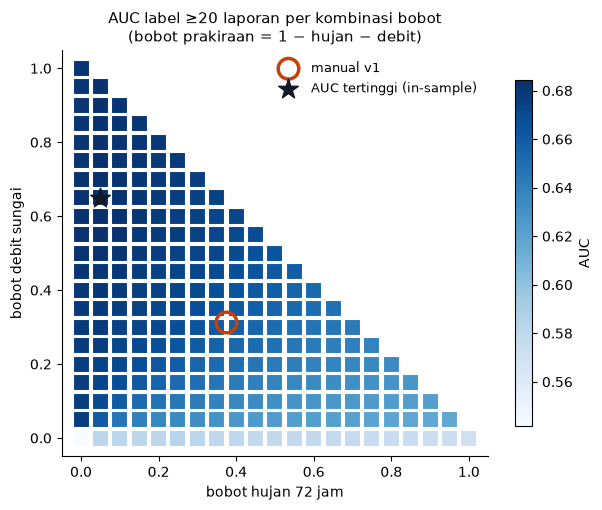

In [6]:
best = g.loc[g[f"auc_ge{MAIN}"].idxmax()]
fig, ax = plt.subplots(figsize=(6.2, 5.2))
sc = ax.scatter(g["rain_72h"], g["river"], c=g[f"auc_ge{MAIN}"], cmap="Blues", marker="s", s=150, edgecolors="white", linewidths=1.5)
ax.scatter([SCHEMES["manual-v1"]["rain_72h"]], [SCHEMES["manual-v1"]["river"]], s=220, facecolors="none", edgecolors="#c2410c", linewidths=2.5, label="manual v1")
ax.scatter([best["rain_72h"]], [best["river"]], s=220, marker="*", color="#111827", label="AUC tertinggi (in-sample)")
ax.set_xlabel("bobot hujan 72 jam"); ax.set_ylabel("bobot debit sungai")
ax.set_title(f"AUC label ≥{MAIN} laporan per kombinasi bobot\n(bobot prakiraan = 1 − hujan − debit)", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(sc, ax=ax, label="AUC", shrink=.85)
ax.legend(loc="upper right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig("/tmp/sensitivity_auc.png", dpi=130)

with mlflow.start_run(run_name="uji-kepekaan-grid"):
    mlflow.set_tags({**COMMON_TAGS, "method": "grid simplex 0,05", "validation": "semua hari (in-sample)"})
    mlflow.log_param("n_kombinasi", len(grid))
    for k in LABELS:
        for key, v in summary[k].items():
            mlflow.log_metric(f"{key.replace(' ', '_')}_auc_ge{k}", float(v))
    g.to_csv("/tmp/sensitivity_grid.csv", index=False)
    mlflow.log_artifact("/tmp/sensitivity_grid.csv")
    mlflow.log_artifact("/tmp/sensitivity_auc.png")
print("tertinggi (in-sample):", best[list(bt.COMPONENTS)].round(2).to_dict(), "AUC", round(best[f"auc_ge{MAIN}"], 3))
plt.show()

Kombinasi dengan AUC tertinggi di grid **dipilih dengan melihat semua data**, jadi angkanya optimistis dan tidak bisa langsung dipakai. Untuk menilai bobot dari data secara jujur, bobot harus dipilih tanpa melihat musim yang dipakai menguji. Itu dilakukan di bagian berikut.

## 4. Bobot dari data: regresi logistik non-negatif, *leave-one-season-out*

Untuk tiap musim: latih regresi logistik pada 7 musim lain dengan koefisien dipaksa ≥ 0, normalkan koefisiennya menjadi bobot, lalu beri skor hari-hari di musim yang disisihkan. Skor dari 8 musim uji digabung, lalu dihitung AUC dan AP-nya. Bobot manual dinilai pada hari yang sama, jadi perbandingannya adil.

In [7]:
loso = {}
for k in LABELS:
    oof, folds = bt.loso(df, Y[k], bt.logreg_scorer(l2=1e-3))
    loso[k] = {"oof": oof, "folds": pd.DataFrame(folds)}

folds = loso[MAIN]["folds"].set_index("season")
folds.index = [f"{s}/{str(s + 1)[2:]}" for s in folds.index]
folds

,n_events,w_rain_72h,w_forecast,w_river
2017/18,12,0.355,0.190,0.455
2018/19,2,0.174,0.108,0.718
2019/20,11,0.184,0.011,0.805
2020/21,6,0.158,0.000,0.842
2021/22,1,0.231,0.123,0.646
2022/23,0,0.209,0.114,0.677
2023/24,4,0.248,0.079,0.672
2024/25,5,0.134,0.170,0.696


In [8]:
cmp_rows = []
for k in LABELS:
    learned = bt.metrics(Y[k], loso[k]["oof"])
    manual = bt.metrics(Y[k], scores["manual-v1"])
    cmp_rows.append({"label": f"≥{k}", "AUC manual": manual["auc"], "AUC dari data (LOSO)": learned["auc"],
                     "AP manual": manual["ap"], "AP dari data (LOSO)": learned["ap"],
                     "proporsi hari banjir": Y[k].mean()})
comparison = pd.DataFrame(cmp_rows).set_index("label")

wf = loso[MAIN]["folds"][[f"w_{c}" for c in bt.COMPONENTS]]
with mlflow.start_run(run_name="logreg-nonneg-loso"):
    mlflow.set_tags({**COMMON_TAGS, "method": "regresi logistik koefisien ≥0, L2=1e-3", "validation": "leave-one-season-out (8 musim)"})
    mlflow.log_params({f"w_{c}_mean": round(wf[f"w_{c}"].mean(), 4) for c in bt.COMPONENTS})
    mlflow.log_params({f"w_{c}_std": round(wf[f"w_{c}"].std(), 4) for c in bt.COMPONENTS})
    for k in LABELS:
        m = bt.metrics(Y[k], loso[k]["oof"])
        mlflow.log_metrics({f"auc_ge{k}": m["auc"], f"ap_ge{k}": m["ap"]})
    loso[MAIN]["folds"].to_csv("/tmp/loso_folds.csv", index=False)
    mlflow.log_artifact("/tmp/loso_folds.csv")
comparison

🏃 View run logreg-nonneg-loso at: http://127.0.0.1:5000/#/experiments/3/runs/7e72b3395c914324b6f742906acbf97c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


,AUC manual,AUC dari data (LOSO),AP manual,AP dari data (LOSO),proporsi hari banjir
label,,,,,
≥5,0.591,0.590,0.197,0.185,0.136
≥20,0.661,0.662,0.062,0.050,0.028
≥50,0.777,0.757,0.056,0.048,0.008


Bobot per fold di tabel atas menunjukkan **seberapa stabil** bobot hasil belajar. Kalau bobotnya berubah jauh setiap kali satu musim dikeluarkan, model sedang mengikuti kebetulan di musim-musim tertentu, bukan pola yang konsisten.

## 5. Apakah selisihnya nyata? Bootstrap per musim

Musim di-*resample* utuh 2.000 kali, bukan per hari, karena hari-hari dalam satu musim saling berkaitan. Untuk tiap sampel dihitung selisih AUC: bobot dari data (LOSO) dikurangi bobot manual.

In [9]:
boot = {}
for k in LABELS:
    d = bt.season_bootstrap(df, Y[k], scores["manual-v1"], loso[k]["oof"])
    boot[k] = {"selisih AUC (median)": np.median(d), "IK 95% bawah": np.quantile(d, .025),
               "IK 95% atas": np.quantile(d, .975), "P(dari data lebih baik)": (d > 0).mean()}
boot_df = pd.DataFrame(boot).T
boot_df.index = [f"≥{k}" for k in boot_df.index]
with mlflow.start_run(run_name="bootstrap-selisih-auc"):
    mlflow.set_tags({**COMMON_TAGS, "method": "bootstrap per musim, 2000 sampel", "compare": "logreg-nonneg-loso minus manual-v1"})
    for k in LABELS:
        mlflow.log_metrics({f"delta_auc_median_ge{k}": float(boot[k]["selisih AUC (median)"]),
                            f"delta_auc_ci_low_ge{k}": float(boot[k]["IK 95% bawah"]),
                            f"delta_auc_ci_high_ge{k}": float(boot[k]["IK 95% atas"])})
boot_df

🏃 View run bootstrap-selisih-auc at: http://127.0.0.1:5000/#/experiments/3/runs/465f2fb598314d268aadc496a3c2987c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


,selisih AUC (median),IK 95% bawah,IK 95% atas,P(dari data lebih baik)
≥5,-4.777e-05,-0.011,8.272e-03,0.498
≥20,1.022e-03,-0.014,2.010e-02,0.551
≥50,-2.077e-02,-0.065,4.155e-04,0.026


In [10]:
# Level manual v1 (skor penuh termasuk riwayat banjir Jakarta = 20 poin) vs peluang banjir
full = np.round(100 * (0.8 * scores["manual-v1"] + 0.2))
lv = pd.cut(full, [-1, 39, 69, 100], labels=["Rendah", "Sedang", "Tinggi"])
pd.DataFrame({"hari": pd.Series(lv).value_counts().sort_index(),
              **{f"peluang ≥{k}": pd.Series(Y[k]).groupby(lv, observed=False).mean() for k in LABELS}})

,hari,peluang ≥5,peluang ≥20,peluang ≥50
Rendah,968,0.107,0.017,0.002
Sedang,441,0.184,0.048,0.016
Tinggi,41,0.293,0.098,0.073


## Kesimpulan

**Bobot manual v1 tetap dipakai.** Bobot yang dipelajari dari data tidak lebih baik.

| Bukti | Hasil |
|---|---|
| Uji kepekaan, label ≥20 | Hampir semua kombinasi bobot memberi AUC 0,65–0,68. Bobot manual (0,661) ada di median grid, hanya 0,023 di bawah kombinasi terbaik in-sample (0,684). Permukaannya **landai**: pilihan bobot bukan faktor penentu |
| Bobot dari data (LOSO) | AUC **sama** dengan manual untuk ≥5 dan ≥20 (0,590 vs 0,591; 0,662 vs 0,661), **lebih rendah** untuk ≥50 (0,757 vs 0,777). AP lebih rendah di ketiga label |
| Bootstrap per musim | Selisih AUC ≈ 0, dan interval 95% memuat 0 untuk ≥5 dan ≥20. Untuk ≥50, bobot dari data lebih baik di hanya 2,6% sampel |
| Stabilitas bobot dari data | Bobot debit berubah 0,46–0,84 antar fold, prakiraan 0,00–0,19. Model menyesuaikan diri dengan musim-musim tertentu |
| Level manual v1 | Peluang hari banjir ≥20 laporan: Rendah 1,7%, Sedang 4,8%, **Tinggi 9,8%**. Untuk ≥50 laporan: 0,2% → 1,6% → 7,3% |

**Yang bisa dipelajari:**

1. **Debit sungai komponen terkuat.** Regresi logistik selalu memberinya bobot terbesar, dan hanya-debit menang in-sample untuk ≥20 (AUC 0,681). Untuk banjir besar (≥50), gabungan dengan hujan justru lebih baik. Karena itu bobot debit tidak dinaikkan berdasarkan satu label saja.
2. **Batasnya ada di input, bukan di bobot.** Selisih antara bobot manual dan kombinasi terbaik hanya sekitar 0,02 AUC. Yang membatasi adalah ERA5 (±25 km) yang melewatkan hujan ekstrem lokal: banjir 25 Feb 2020 hanya tercatat 10 mm. Usaha lebih baik dipakai untuk input yang lebih tajam, yaitu Model A, peringatan dini BMKG, dan arsip prakiraan asli, daripada menyetel bobot.
3. **Komponen prakiraan di sini terlalu optimistis** karena memakai hujan yang benar-benar terjadi, dan tetap lemah (AUC 0,54 sendirian). Bobotnya perlu dinilai ulang setelah arsip snapshot prakiraan cukup panjang, sekitar satu musim hujan.

**Keputusan:** `risk-v1` tetap. Semua run tercatat di MLflow, eksperimen `siaganusa-indeks-risiko`. Uji ini diulang saat arsip prakiraan sudah satu musim penuh.